# EMQA_L1_profile_intraday

**Intraday price profile, Romania and Germany, 2019 vs 2025**

Energy Markets Quantitative Analysis (EMQA), Lecture 1 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L1/EMQA_L1_profile_intraday/EMQA_L1_profile_intraday.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

Mean day-ahead price by hour of the day (CET/CEST) in Romania and Germany-Luxembourg, calendar years 2019 and 2025: solar moved the cheapest hour of the day from the night to midday.

**Data:** calendar years 2019 and 2025, hourly. **Source:** energy-charts.info (Fraunhofer ISE); prices from the exchanges OPCOM (RO), IBEX (BG), HUPX (HU), EPEX SPOT (DE-LU), via ENTSO-E.

The numbers printed below are those on the slide; the tag `[key]` is their name in `lectures/L1/L1_numbers.json`.

In [2]:
import json
import urllib.request
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
warnings.filterwarnings('ignore')

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.titlesize': 11.5, 'axes.labelsize': 11,
    'legend.fontsize': 10.5, 'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}   # fixed colour per bidding zone
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
ZONE_LS = {'RO': '-', 'BG': '--', 'HU': '-.', 'DE_LU': ':'}
ZONES = ['RO', 'BG', 'HU', 'DE_LU']
ZONE_NAME = {'RO': 'Romania (OPCOM PZU)', 'BG': 'Bulgaria (IBEX)', 'HU': 'Hungary (HUPX)', 'DE_LU': 'Germany-Luxembourg'}
MON_EN = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
MON1 = ['J', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D']


def legend_bottom(fig, ncol=4, y=0.0):
    """One legend centred under the axes, outside the plotting area."""
    handles, labels = [], []
    for ax in fig.axes:
        for h, l_ in zip(*ax.get_legend_handles_labels()):
            if l_ not in labels:
                handles.append(h)
                labels.append(l_)
    if handles:
        fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, y), frameon=False,
                   handlelength=2.0, columnspacing=1.2)


def fl(x, k=4):
    """Round as on the slides."""
    return None if x is None or np.isnan(float(x)) else round(float(x), k)


def d(ts):
    return pd.Timestamp(ts).strftime('%Y-%m-%d')


def show(key, label, value):
    """Print a number of the slide; [key] = its name in lectures/L1/L1_numbers.json."""
    print(f'{label} = {value}   [{key}]')

## Data
Real series from the course repository (see `data/SOURCES.md`), cut at the last complete month; missing values stay missing.

In [3]:
# data cut-off: last complete calendar month common to the Romanian prices and the generation data
_p = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', usecols=['date_cet', 'RO'], parse_dates=['date_cet']).set_index('date_cet')['RO']
_g = pd.read_csv(DATA + 'generation_ro_mw_daily_cet.csv', usecols=['date_cet', 'hydro_run_of_river'],
                 parse_dates=['date_cet']).set_index('date_cet')['hydro_run_of_river']
_last = min(_p.dropna().index.max(), _g.dropna().index.max())
END = pd.Timestamp(((_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
END_UTC = (END + pd.Timedelta(days=1)).tz_localize('Europe/Brussels').tz_convert('UTC')   # end of the CET day, in UTC
Y = END.year
print('data cut-off:', END.date())

# hourly day-ahead prices (15-min prices averaged to the hour from Oct 2025), CET/CEST clock
H = pd.read_csv(DATA + 'power_da_prices_hourly_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
H.index = H.index.tz_convert('Europe/Brussels')
H = H.loc[:str(END.date())]

data cut-off: 2026-10-31


## Computation

In [4]:
hh = H.copy()
hh['hour'] = hh.index.hour
prof = {y: hh.loc[str(y)].groupby('hour')[['RO', 'DE_LU']].mean() for y in [2019, 2025]}
for y in [2019, 2025]:
    pr = prof[y]['RO']
    show(f'season.intraday.RO_{y}.min_h', f'RO {y}: cheapest hour', int(pr.idxmin()))
    show(f'season.intraday.RO_{y}.min', f'RO {y}: lowest hourly mean, EUR/MWh', fl(pr.min(), 1))
    show(f'season.intraday.RO_{y}.max', f'RO {y}: highest hourly mean, EUR/MWh', fl(pr.max(), 1))
    show(f'season.intraday.RO_{y}.ratio_19_13', f'RO {y}: price at 19:00 / price at 13:00', fl(pr.loc[19] / pr.loc[13], 2))

RO 2019: cheapest hour = 3   [season.intraday.RO_2019.min_h]
RO 2019: lowest hourly mean, EUR/MWh = 30.2   [season.intraday.RO_2019.min]
RO 2019: highest hourly mean, EUR/MWh = 67.4   [season.intraday.RO_2019.max]
RO 2019: price at 19:00 / price at 13:00 = 1.3   [season.intraday.RO_2019.ratio_19_13]
RO 2025: cheapest hour = 13   [season.intraday.RO_2025.min_h]
RO 2025: lowest hourly mean, EUR/MWh = 58.8   [season.intraday.RO_2025.min]
RO 2025: highest hourly mean, EUR/MWh = 182.5   [season.intraday.RO_2025.max]
RO 2025: price at 19:00 / price at 13:00 = 3.11   [season.intraday.RO_2025.ratio_19_13]


## Chart

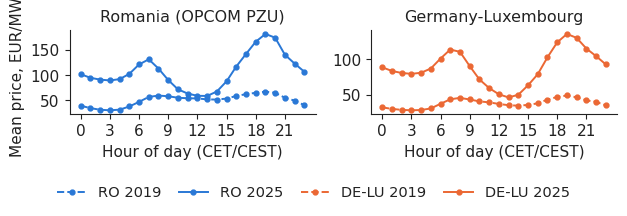

In [5]:
ZL = {'RO': 'RO', 'DE_LU': 'DE-LU'}
fig, axs = plt.subplots(1, 2, figsize=(6.4, 2.2))
for ax, z in zip(axs, ['RO', 'DE_LU']):
    for y, ls in [(2019, '--'), (2025, '-')]:
        ax.plot(prof[y].index, prof[y][z], color=PAL[z], ls=ls, marker='o', ms=3.5, label=f'{ZL[z]} {y}')
    ax.set_title(ZONE_NAME[z])
    ax.set_xlabel('Hour of day (CET/CEST)')
    ax.set_xticks(range(0, 24, 3))
axs[0].set_ylabel('Mean price, EUR/MWh')
legend_bottom(fig, ncol=4)
fig.tight_layout(rect=(0, 0.17, 1, 1))
plt.savefig('profile_intraday.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()